# Cool Roofing Cost & Impact Predictor

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, f1_score, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import joblib
import os

## Step 1 — Load Data

In [2]:
df = pd.read_csv('cool_roofing_data.csv')
df.head()

,building_id,location_type,building_size,building_age,cool_roofing_quality,roofing_type,cool_roofing_method,cool_roofing_cost,avg_roof_temperature_before,num_ac_units,avg_units_before,avg_roof_temperature_after,avg_units_after,customer_given_rating,customer_referral
0,1,urban,600.0,17.0,intermediate,concrete_flat,sheet,208500,35.16,0.0,8,29.73,8,1,False
1,2,intermediate,1700.0,11.0,intermediate,concrete_flat,tiles_with_coating,1484100,31.67,1.0,52,24.74,23,5,False
2,3,dense_urban,2500.0,27.0,high,sheet,sheet_with_coating,3117100,37.99,1.0,147,28.08,64,3,False
3,4,urban,2000.0,34.0,high,tiles,basic_coating,2232600,34.44,2.0,197,29.14,112,2,False
4,5,rural,1000.0,14.0,basic,sheet,basic_coating,259900,30.87,0.0,13,27.76,13,3,False


In [3]:
df.shape

(2500, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   building_id                  2500 non-null   int64  
 1   location_type                2476 non-null   str    
 2   building_size                2472 non-null   float64
 3   building_age                 2477 non-null   float64
 4   cool_roofing_quality         2500 non-null   str    
 5   roofing_type                 2500 non-null   str    
 6   cool_roofing_method          2500 non-null   str    
 7   cool_roofing_cost            2500 non-null   int64  
 8   avg_roof_temperature_before  2500 non-null   float64
 9   num_ac_units                 2469 non-null   float64
 10  avg_units_before             2500 non-null   int64  
 11  avg_roof_temperature_after   2500 non-null   float64
 12  avg_units_after              2500 non-null   int64  
 13  customer_given_rating        

In [5]:
df.describe()

,building_id,building_size,building_age,cool_roofing_cost,avg_roof_temperature_before,num_ac_units,avg_units_before,avg_roof_temperature_after,avg_units_after,customer_given_rating
count,2500.00000,2472.000000,2477.000000,2.500000e+03,2500.000000,2469.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,1419.377023,25.389180,1.093520e+06,33.926908,1.127987,91.806000,27.810932,46.021600,3.218400
std,721.83216,567.450382,14.385794,8.081023e+05,10.401122,0.961486,80.415286,9.939717,38.952351,1.152056
min,1.00000,300.000000,1.000000,5.530000e+04,22.980000,0.000000,0.000000,17.810000,0.000000,1.000000
25%,625.75000,1000.000000,13.000000,5.024750e+05,30.337500,0.000000,24.000000,24.630000,19.000000,2.000000
50%,1250.50000,1300.000000,26.000000,8.609000e+05,33.065000,1.000000,75.500000,26.910000,35.000000,3.000000
75%,1875.25000,1800.000000,38.000000,1.476450e+06,35.432500,2.000000,129.000000,29.042500,61.000000,4.000000
max,2500.00000,3000.000000,50.000000,5.046600e+06,120.000000,3.000000,500.000000,120.000000,311.000000,5.000000


## Step 2 — Data Cleaning

In [6]:
# Check for problems
print('Missing values:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('120C sentinel in temp_before:', (df['avg_roof_temperature_before'] == 120).sum())
print('120C sentinel in temp_after: ', (df['avg_roof_temperature_after']  == 120).sum())
print('Non-positive building_size:  ', (df['building_size'] <= 0).sum())
print('Non-positive cost:           ', (df['cool_roofing_cost'] <= 0).sum())

Missing values:
 building_id                     0
location_type                  24
building_size                  28
building_age                   23
cool_roofing_quality            0
roofing_type                    0
cool_roofing_method             0
cool_roofing_cost               0
avg_roof_temperature_before     0
num_ac_units                   31
avg_units_before                0
avg_roof_temperature_after      0
avg_units_after                 0
customer_given_rating           0
customer_referral               0
dtype: int64
Duplicate rows: 0
120C sentinel in temp_before: 32
120C sentinel in temp_after:  26
Non-positive building_size:   0
Non-positive cost:            0


In [7]:
# 120 degrees is physically impossible for a rooftop — sensor error/placeholder
# Mark as NaN so rows are still usable for non-temperature tasks
df.loc[df['avg_roof_temperature_before'] == 120, 'avg_roof_temperature_before'] = np.nan
df.loc[df['avg_roof_temperature_after']  == 120, 'avg_roof_temperature_after']  = np.nan

# Drop physically impossible rows
df = df[df['building_size'] > 0]
df = df[df['cool_roofing_cost'] > 0]
df = df.reset_index(drop=True)
print('Rows after cleaning:', len(df))

Rows after cleaning: 2472


In [8]:
# Create targets
df['temperature_drop'] = df['avg_roof_temperature_before'] - df['avg_roof_temperature_after']
df['units_saved']      = df['avg_units_before'] - df['avg_units_after']
df['high_rating']      = (df['customer_given_rating'] >= 4).astype(int)
df['referral']         = df['customer_referral'].astype(int)

df[['temperature_drop', 'units_saved', 'high_rating', 'referral']].head()

,temperature_drop,units_saved,high_rating,referral
0,5.43,0,0,0
1,6.93,29,1,0
2,9.91,83,0,0
3,5.30,85,0,0
4,3.11,0,0,0


## Step 3 — EDA

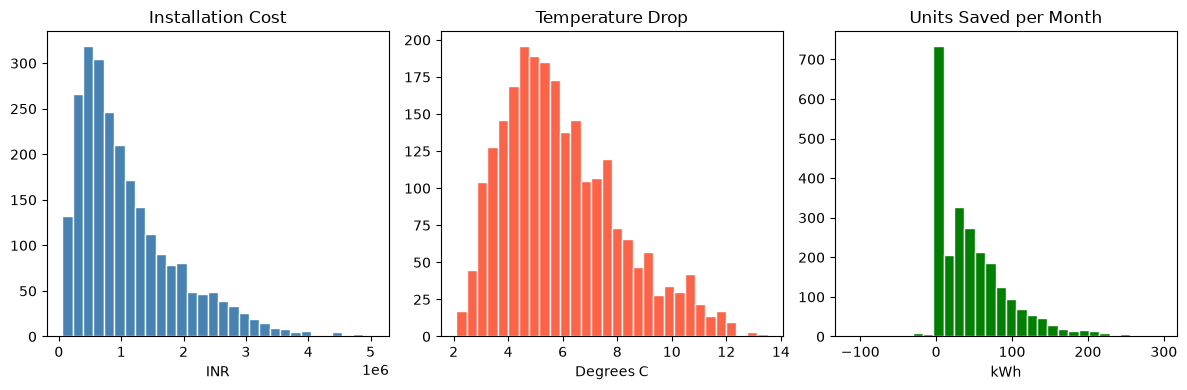

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(df['cool_roofing_cost'], bins=30, color='steelblue', edgecolor='white')
plt.title('Installation Cost')
plt.xlabel('INR')

plt.subplot(1, 3, 2)
plt.hist(df['temperature_drop'].dropna(), bins=30, color='tomato', edgecolor='white')
plt.title('Temperature Drop')
plt.xlabel('Degrees C')

plt.subplot(1, 3, 3)
plt.hist(df['units_saved'], bins=30, color='green', edgecolor='white')
plt.title('Units Saved per Month')
plt.xlabel('kWh')

plt.tight_layout()
plt.show()

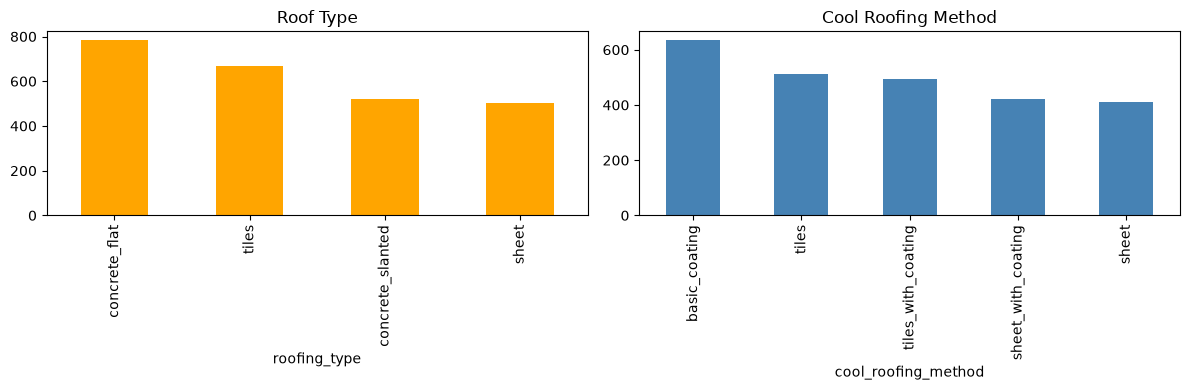

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['roofing_type'].value_counts().plot(kind='bar', ax=axes[0], color='orange', title='Roof Type')
df['cool_roofing_method'].value_counts().plot(kind='bar', ax=axes[1], color='steelblue', title='Cool Roofing Method')
plt.tight_layout()
plt.show()

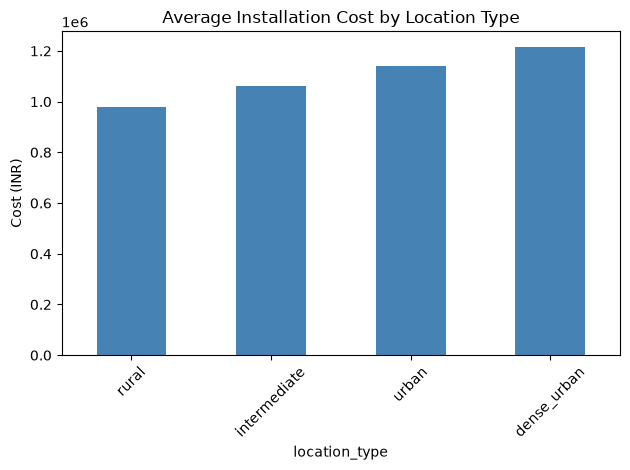

In [11]:
df.groupby('location_type')['cool_roofing_cost'].mean().sort_values().plot(kind='bar', color='steelblue')
plt.title('Average Installation Cost by Location Type')
plt.ylabel('Cost (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 4 — Feature Engineering

Encode categorical columns. Only use pre-installation features (no leakage).

In [12]:
cat_cols = ['location_type', 'cool_roofing_quality', 'roofing_type', 'cool_roofing_method']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=False)
print('Shape after encoding:', df_encoded.shape)

base_num = ['building_size', 'building_age', 'num_ac_units']
base_cat = [c for c in df_encoded.columns
            if c.startswith('location_type_') or
               c.startswith('cool_roofing_quality_') or
               c.startswith('roofing_type_') or
               c.startswith('cool_roofing_method_')]
BASE = base_num + base_cat
print('Total base features:', len(BASE))

Shape after encoding: (2472, 31)
Total base features: 19


## Step 5 — Task 1: Installation Cost (Regression)

In [13]:
X = df_encoded[BASE].fillna(df_encoded[BASE].median())
y = df_encoded['cool_roofing_cost']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)

Train: (1730, 19) | Val: (371, 19) | Test: (371, 19)


In [14]:
# Baseline
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print('Baseline MAE: ', round(mean_absolute_error(y_val, baseline.predict(X_val)), 0), 'INR')
print('Baseline RMSE:', round(np.sqrt(mean_squared_error(y_val, baseline.predict(X_val))), 0), 'INR')

Baseline MAE:  608878.0 INR
Baseline RMSE: 807853.0 INR


In [15]:
rf_cost = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf_cost.fit(X_train, y_train)
rf_cost.score(X_test, y_test)

0.9797261660887044

In [16]:
y_pred = rf_cost.predict(X_test)
print('Test MAE: ', round(mean_absolute_error(y_test, y_pred), 0), 'INR')
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 0), 'INR')

Test MAE:  69426.0 INR
Test RMSE: 111562.0 INR


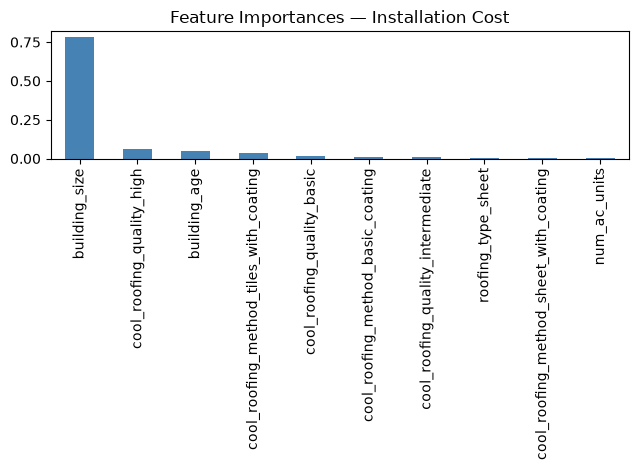

In [17]:
# Output:
pd.Series(rf_cost.feature_importances_, index=BASE).sort_values(ascending=False)[:10].plot(kind='bar', color='steelblue')
plt.title('Feature Importances — Installation Cost')
plt.tight_layout()
plt.show()

## Step 6 — Task 2: Roof Temperature Drop (Regression)

In [18]:
df_temp = df_encoded.dropna(subset=['temperature_drop']).copy()
print('Rows available:', len(df_temp))

TEMP_FEATS = BASE + ['avg_roof_temperature_before']
X = df_temp[TEMP_FEATS].fillna(df_temp[TEMP_FEATS].median())
y = df_temp['temperature_drop']

X_train, X_temp2, y_train, y_temp2 = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test       = train_test_split(X_temp2, y_temp2, test_size=0.50, random_state=42)

Rows available: 2414


In [19]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print('Baseline MAE: ', round(mean_absolute_error(y_val, baseline.predict(X_val)), 3), 'degrees C')
print('Baseline RMSE:', round(np.sqrt(mean_squared_error(y_val, baseline.predict(X_val))), 3), 'degrees C')

Baseline MAE:  1.67 degrees C
Baseline RMSE: 2.069 degrees C


In [20]:
rf_temp = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf_temp.fit(X_train, y_train)
rf_temp.score(X_test, y_test)

0.935210500008606

In [21]:
y_pred = rf_temp.predict(X_test)
print('Test MAE: ', round(mean_absolute_error(y_test, y_pred), 3), 'degrees C')
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 3), 'degrees C')

Test MAE:  0.463 degrees C
Test RMSE: 0.562 degrees C


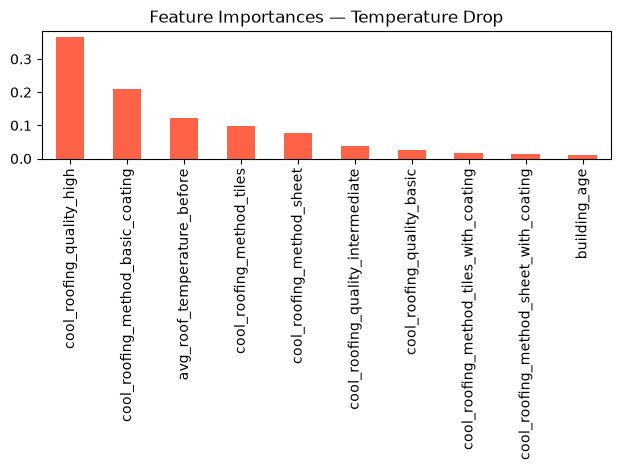

In [22]:
# Output:
pd.Series(rf_temp.feature_importances_, index=TEMP_FEATS).sort_values(ascending=False)[:10].plot(kind='bar', color='tomato')
plt.title('Feature Importances — Temperature Drop')
plt.tight_layout()
plt.show()

## Step 7 — Task 3: Electricity Units Saved (Regression)

In [23]:
UNITS_FEATS = BASE + ['avg_units_before']
X = df_encoded[UNITS_FEATS].fillna(df_encoded[UNITS_FEATS].median())
y = df_encoded['units_saved']

X_train, X_temp3, y_train, y_temp3 = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test       = train_test_split(X_temp3, y_temp3, test_size=0.50, random_state=42)

In [24]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print('Baseline MAE: ', round(mean_absolute_error(y_val, baseline.predict(X_val)), 2), 'kWh')
print('Baseline RMSE:', round(np.sqrt(mean_squared_error(y_val, baseline.predict(X_val))), 2), 'kWh')

Baseline MAE:  39.74 kWh
Baseline RMSE: 52.05 kWh


In [25]:
rf_units = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf_units.fit(X_train, y_train)
rf_units.score(X_test, y_test)

0.9436790877196292

In [26]:
y_pred = rf_units.predict(X_test)
print('Test MAE: ', round(mean_absolute_error(y_test, y_pred), 2), 'kWh')
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 2), 'kWh')

Test MAE:  5.41 kWh
Test RMSE: 11.58 kWh


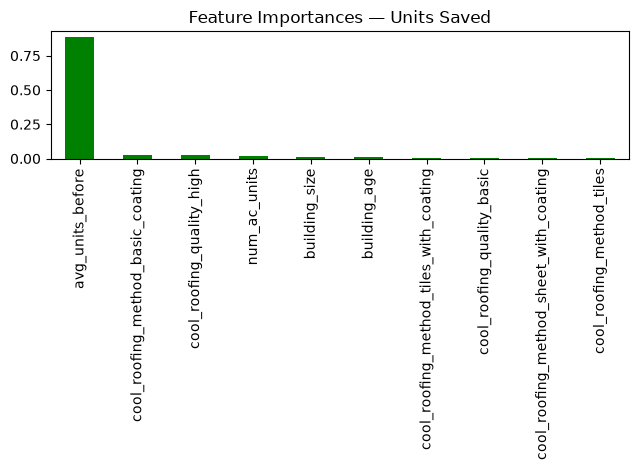

In [27]:
# Output:
pd.Series(rf_units.feature_importances_, index=UNITS_FEATS).sort_values(ascending=False)[:10].plot(kind='bar', color='green')
plt.title('Feature Importances — Units Saved')
plt.tight_layout()
plt.show()

## Step 8 — Task 4: High Customer Rating (Classification)

Target: 1 if rating >= 4, else 0

In [28]:
RATING_FEATS = BASE + ['avg_roof_temperature_before', 'avg_units_before']
X = df_encoded[RATING_FEATS].fillna(df_encoded[RATING_FEATS].median())
y = df_encoded['high_rating']

X_train, X_temp4, y_train, y_temp4 = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test       = train_test_split(X_temp4, y_temp4, test_size=0.50, random_state=42, stratify=y_temp4)

print('Class distribution:', y_train.value_counts().to_dict())

Class distribution: {0: 999, 1: 731}


In [29]:
baseline = DummyClassifier(strategy='stratified', random_state=42)
baseline.fit(X_train, y_train)
print('Baseline Accuracy:', round(accuracy_score(y_val, baseline.predict(X_val)), 3))

Baseline Accuracy: 0.561


In [30]:
rf_rating = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_rating.fit(X_train, y_train)
rf_rating.score(X_test, y_test)

0.6549865229110512

In [31]:
y_pred   = rf_rating.predict(X_test)
y_proba  = rf_rating.predict_proba(X_test)[:, 1]

print('Test Accuracy:            ', round(accuracy_score(y_test, y_pred), 3))
print('Test MAE (prob vs actual):', round(mean_absolute_error(y_test, y_proba), 3))
print('Test ROC-AUC:             ', round(roc_auc_score(y_test, y_proba), 3))

Test Accuracy:             0.655
Test MAE (prob vs actual): 0.401
Test ROC-AUC:              0.728


Confusion Matrix:
[[145  70]
 [ 58  98]]


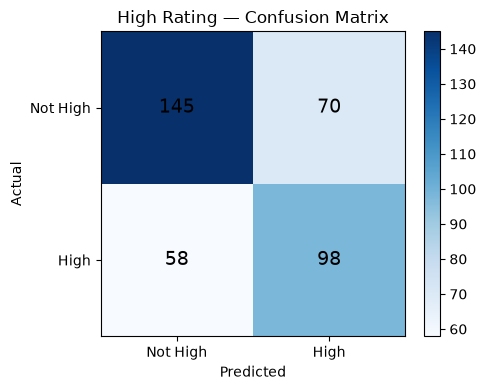

In [32]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['Not High', 'High'])
plt.yticks([0, 1], ['Not High', 'High'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('High Rating — Confusion Matrix')
plt.tight_layout()
plt.show()

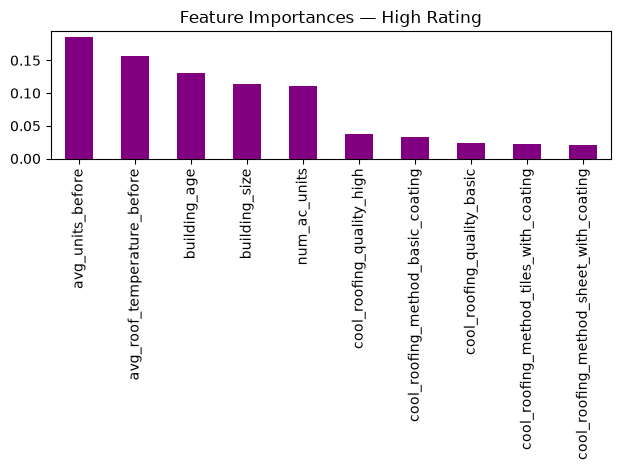

In [33]:
# Output:
pd.Series(rf_rating.feature_importances_, index=RATING_FEATS).sort_values(ascending=False)[:10].plot(kind='bar', color='purple')
plt.title('Feature Importances — High Rating')
plt.tight_layout()
plt.show()

## Step 9 — Task 5: Customer Referral (Classification)

In [34]:
REFERRAL_FEATS = BASE + ['avg_roof_temperature_before', 'avg_units_before']
X = df_encoded[REFERRAL_FEATS].fillna(df_encoded[REFERRAL_FEATS].median())
y = df_encoded['referral']

X_train, X_temp5, y_train, y_temp5 = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test       = train_test_split(X_temp5, y_temp5, test_size=0.50, random_state=42, stratify=y_temp5)

print('Class distribution:', y_train.value_counts().to_dict())

Class distribution: {0: 1105, 1: 625}


In [35]:
baseline = DummyClassifier(strategy='stratified', random_state=42)
baseline.fit(X_train, y_train)
print('Baseline Accuracy:', round(accuracy_score(y_val, baseline.predict(X_val)), 3))
print('Baseline F1:      ', round(f1_score(y_val, baseline.predict(X_val)), 3))

Baseline Accuracy: 0.571
Baseline F1:       0.395


In [36]:
rf_ref = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_ref.fit(X_train, y_train)
rf_ref.score(X_test, y_test)

0.6199460916442049

In [37]:
y_pred  = rf_ref.predict(X_test)
y_proba = rf_ref.predict_proba(X_test)[:, 1]

print('Test Accuracy:', round(accuracy_score(y_test, y_pred), 3))
print('Test F1-score:', round(f1_score(y_test, y_pred), 3))
print('Test ROC-AUC: ', round(roc_auc_score(y_test, y_proba), 3))

Test Accuracy: 0.62
Test F1-score: 0.505
Test ROC-AUC:  0.646


Confusion Matrix:
[[158  79]
 [ 62  72]]


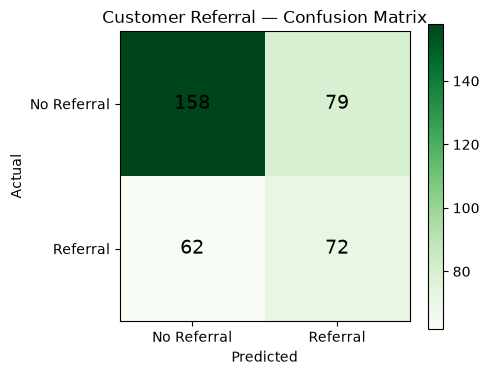

In [38]:
cm_ref = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm_ref)

plt.figure(figsize=(5, 4))
plt.imshow(cm_ref, cmap='Greens')
plt.colorbar()
plt.xticks([0, 1], ['No Referral', 'Referral'])
plt.yticks([0, 1], ['No Referral', 'Referral'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_ref[i, j], ha='center', va='center', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Customer Referral — Confusion Matrix')
plt.tight_layout()
plt.show()

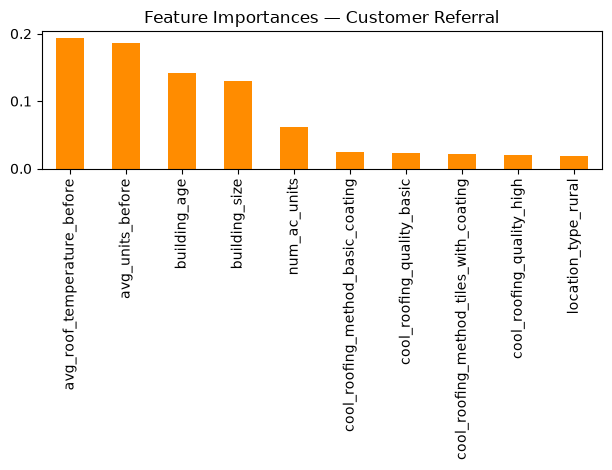

In [39]:
# Output:
pd.Series(rf_ref.feature_importances_, index=REFERRAL_FEATS).sort_values(ascending=False)[:10].plot(kind='bar', color='darkorange')
plt.title('Feature Importances — Customer Referral')
plt.tight_layout()
plt.show()

## Step 10 — Final Results Summary

In [40]:
# Re-run predictions on each saved test set for clean summary
# (variables still in memory from cells above)

print('='*55)
print('FINAL TEST SET METRICS')
print('='*55)
print()

FINAL TEST SET METRICS



In [41]:
# To get clean numbers, re-run each task's test predictions

# Task 1 — Cost
X1 = df_encoded[BASE].fillna(df_encoded[BASE].median())
y1 = df_encoded['cool_roofing_cost']
_, Xte1, _, yte1 = train_test_split(X1, y1, test_size=0.30, random_state=42)
_, Xte1, _, yte1 = train_test_split(Xte1, yte1, test_size=0.50, random_state=42)
p1 = rf_cost.predict(Xte1)
print('Task 1 — Installation Cost')
print('  MAE : ', round(mean_absolute_error(yte1, p1), 0), 'INR')
print('  RMSE:', round(np.sqrt(mean_squared_error(yte1, p1)), 0), 'INR')
print()

# Task 2 — Temp drop
df_t = df_encoded.dropna(subset=['temperature_drop'])
X2   = df_t[TEMP_FEATS].fillna(df_t[TEMP_FEATS].median())
y2   = df_t['temperature_drop']
_, Xte2, _, yte2 = train_test_split(X2, y2, test_size=0.30, random_state=42)
_, Xte2, _, yte2 = train_test_split(Xte2, yte2, test_size=0.50, random_state=42)
p2 = rf_temp.predict(Xte2)
print('Task 2 — Roof Temperature Drop')
print('  MAE : ', round(mean_absolute_error(yte2, p2), 3), 'degrees C')
print('  RMSE:', round(np.sqrt(mean_squared_error(yte2, p2)), 3), 'degrees C')
print()

# Task 3 — Units saved
X3 = df_encoded[UNITS_FEATS].fillna(df_encoded[UNITS_FEATS].median())
y3 = df_encoded['units_saved']
_, Xte3, _, yte3 = train_test_split(X3, y3, test_size=0.30, random_state=42)
_, Xte3, _, yte3 = train_test_split(Xte3, yte3, test_size=0.50, random_state=42)
p3 = rf_units.predict(Xte3)
print('Task 3 — Electricity Units Saved')
print('  MAE : ', round(mean_absolute_error(yte3, p3), 2), 'kWh')
print('  RMSE:', round(np.sqrt(mean_squared_error(yte3, p3)), 2), 'kWh')
print()

# Task 4 — High rating
X4 = df_encoded[RATING_FEATS].fillna(df_encoded[RATING_FEATS].median())
y4 = df_encoded['high_rating']
_, Xte4, _, yte4 = train_test_split(X4, y4, test_size=0.30, random_state=42, stratify=y4)
_, Xte4, _, yte4 = train_test_split(Xte4, yte4, test_size=0.50, random_state=42, stratify=yte4)
p4 = rf_rating.predict(Xte4)
pb4 = rf_rating.predict_proba(Xte4)[:, 1]
print('Task 4 — High Customer Rating')
print('  Accuracy:', round(accuracy_score(yte4, p4), 3))
print('  MAE (prob vs actual):', round(mean_absolute_error(yte4, pb4), 3))
print()

# Task 5 — Referral
X5 = df_encoded[REFERRAL_FEATS].fillna(df_encoded[REFERRAL_FEATS].median())
y5 = df_encoded['referral']
_, Xte5, _, yte5 = train_test_split(X5, y5, test_size=0.30, random_state=42, stratify=y5)
_, Xte5, _, yte5 = train_test_split(Xte5, yte5, test_size=0.50, random_state=42, stratify=yte5)
p5 = rf_ref.predict(Xte5)
print('Task 5 — Customer Referral')
print('  Accuracy:', round(accuracy_score(yte5, p5), 3))
print('  F1-score:', round(f1_score(yte5, p5), 3))

Task 1 — Installation Cost
  MAE :  69426.0 INR
  RMSE: 111562.0 INR

Task 2 — Roof Temperature Drop
  MAE :  0.463 degrees C
  RMSE: 0.562 degrees C

Task 3 — Electricity Units Saved
  MAE :  5.41 kWh
  RMSE: 11.58 kWh

Task 4 — High Customer Rating
  Accuracy: 0.655
  MAE (prob vs actual): 0.401

Task 5 — Customer Referral
  Accuracy: 0.62
  F1-score: 0.505


## Step 11 — Save Models

In [42]:
os.makedirs('models', exist_ok=True)

joblib.dump(rf_cost,   'models/model_cost.joblib')
joblib.dump(rf_temp,   'models/model_temp_drop.joblib')
joblib.dump(rf_units,  'models/model_units_saved.joblib')
joblib.dump(rf_rating, 'models/model_high_rating.joblib')
joblib.dump(rf_ref,    'models/model_referral.joblib')

joblib.dump(BASE,          'models/features_base.joblib')
joblib.dump(TEMP_FEATS,    'models/features_temp_drop.joblib')
joblib.dump(UNITS_FEATS,   'models/features_units_saved.joblib')
joblib.dump(RATING_FEATS,  'models/features_high_rating.joblib')
joblib.dump(REFERRAL_FEATS,'models/features_referral.joblib')
joblib.dump(list(df_encoded.columns), 'models/encoded_columns.joblib')

print('All models saved to models/')

All models saved to models/
